In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
# 1. parse_dates converts the 'date' column to datetime objects
# 2. dtype={'stn': str, 'wban': str} keeps station IDs formatted with leading zeros
df = pd.read_csv(
    "noaa - 5000.csv",
    parse_dates=["date"],
    dtype={"stn": str, "wban": str}
)

# Display basic information and first 5 rows
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (5000, 33)


,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,010020,99999,2025-07-04,2025,7,4,42.1,4,38.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
1,010020,99999,2025-04-30,2025,4,30,7.6,4,3.8,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
2,010020,99999,2025-04-19,2025,4,19,2.7,4,-2.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
3,010020,99999,2025-04-20,2025,4,20,4.2,4,-1.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
4,010020,99999,2025-03-05,2025,3,5,14.4,4,10.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0


In [2]:
# Replace NOAA missing value sentinel flags with NaN
missing_flags = [999.9, 9999.9]
cols_to_clean = ["temp", "dewp", "slp", "stp", "visib", "wdsp", "mxpsd", "gust", "max", "min", "sndp"]

for col in cols_to_clean:
    if col in df.columns:
        df[col] = df[col].replace(missing_flags, np.nan)

# Check summary statistics after cleaning
df[["temp", "dewp", "slp", "wdsp", "prcp"]].describe()

,temp,dewp,slp,wdsp,prcp
count,5000.000000,4765.000000,3443.000000,4709.000000,5000.000000
mean,59.977860,49.015446,1010.695295,4.796178,3.642022
std,29.405094,26.778858,10.304839,5.153405,18.464065
min,-105.300000,-116.100000,951.200000,0.000000,0.000000
25%,45.800000,35.600000,1005.500000,1.600000,0.000000
50%,68.300000,54.300000,1010.200000,3.400000,0.000000
75%,81.700000,70.200000,1015.300000,6.200000,0.020000
max,109.400000,84.700000,1055.600000,64.100000,99.990000


In [3]:
# Sort values chronologically
df = df.sort_values(by="date")

# Set date as index
df_ts = df.set_index("date")
df_ts.head()

,stn,wban,year,mo,da,temp,count_temp,dewp,count_dewp,slp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,242610,99999,2025,1,1,-28.6,5,-36.0,5,1019.7,...,*,0.03,E,NaN,0,0,1,0,0,0
2025-01-01,422990,99999,2025,1,1,53.0,4,43.5,4,NaN,...,NaN,0.00,I,NaN,0,0,0,0,0,0
2025-01-01,431110,99999,2025,1,1,69.4,4,56.5,4,NaN,...,NaN,0.00,I,NaN,0,0,0,0,0,0
2025-01-01,679690,99999,2025,1,1,82.7,4,NaN,0,NaN,...,NaN,0.00,G,NaN,0,1,0,0,1,0
2025-01-01,432780,99999,2025,1,1,79.7,5,74.9,5,1013.9,...,NaN,0.00,I,NaN,0,0,0,0,0,0


In [4]:
date_index = pd.date_range(start='2025-01-01', periods=365, freq='D')
date_index

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08',
               '2025-01-09', '2025-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[ns]', length=365, freq='D')

In [5]:
# Preview cleaned data types and initial records (without reloading raw data)
print(df[["date", "temp"]].dtypes)
print(df[["date", "temp"]].head())

date    datetime64[ns]
temp           float64
dtype: object
           date  temp
3796 2025-01-01 -28.6
1531 2025-01-01  53.0
1811 2025-01-01  69.4
2804 2025-01-01  82.7
4282 2025-01-01  79.7


In [6]:
# 1. Set the date column as the index
df = df.set_index("date")

# 2. Sort the index chronologically to ensure proper time alignment
df = df.sort_index()

# 3. Demonstrate date-based slicing (e.g., viewing data for July 2025)
july_data = df.loc["2025-07"]
print(f"Number of readings in July 2025: {len(july_data)}")

# Optional: Generate a continuous date range to check for any missing dates
full_range = pd.date_range(
    start=df.index.min(), end=df.index.max(), freq="D"
)
print(f"Total expected days in range: {len(full_range)}")
print(f"Actual rows in dataset: {len(df)}")

Number of readings in July 2025: 710
Total expected days in range: 240
Actual rows in dataset: 5000


In [7]:
# 1. Resample daily temperature ('temp') to monthly average ('ME')
monthly_temp = df["temp"].resample("ME").mean()

# 2. Resample daily temperature to weekly average ('W')
weekly_temp = df["temp"].resample("W").mean()

# Display the first few rows of the resampled monthly data
print("Monthly Average Temperatures:")
print(monthly_temp.head())

Monthly Average Temperatures:
date
2025-01-31    45.653073
2025-02-28    47.156707
2025-03-31    54.819702
2025-04-30    61.089535
2025-05-31    66.567719
Freq: ME, Name: temp, dtype: float64


In [8]:
# Aggregate daily across stations to avoid averaging consecutive station rows
daily_temp = df.groupby("date")["temp"].mean().sort_index()

# 1. Calculate a 30-day rolling window mean on the daily station-aggregated temperature
rolling_30d = daily_temp.rolling(window=30, min_periods=1).mean()

# Preview the rolling average alongside the daily average temperature
comparison_df = pd.DataFrame({"daily_station_avg": daily_temp, "rolling_30d": rolling_30d})
print(comparison_df.tail(10))

            daily_station_avg  rolling_30d
date                                      
2025-08-18          57.119048    69.071019
2025-08-19          60.761538    68.510848
2025-08-20          68.312500    68.626998
2025-08-21          70.275000    68.816659
2025-08-22          66.273684    68.594115
2025-08-23          72.822222    68.674617
2025-08-24          71.506667    68.827773
2025-08-26          59.700000    68.264606
2025-08-27          60.154545    67.826727
2025-08-28          57.200000    67.201661


In [9]:
# 1. Extract calendar attributes directly from the index
df["month"] = df.index.month
df["day_name"] = df.index.day_name()

# 2. Group by month to find the average temperature for each calendar month
monthly_climate_pattern = df.groupby("month")["temp"].mean()
print("Average Temperature by Month:")
print(monthly_climate_pattern)

# 3. Group by day of week to find the average temperature for each day
day_of_week_pattern = df.groupby("day_name")["temp"].mean()
print("\nAverage Temperature by Day of Week:")
print(day_of_week_pattern)

Average Temperature by Month:
month
1    45.653073
2    47.156707
3    54.819702
4    61.089535
5    66.567719
6    67.142985
7    70.449718
8    68.461036
Name: temp, dtype: float64

Average Temperature by Day of Week:
day_name
Friday       57.383106
Monday       61.977727
Saturday     61.177650
Sunday       60.705014
Thursday     58.579714
Tuesday      59.780028
Wednesday    60.724038
Name: temp, dtype: float64


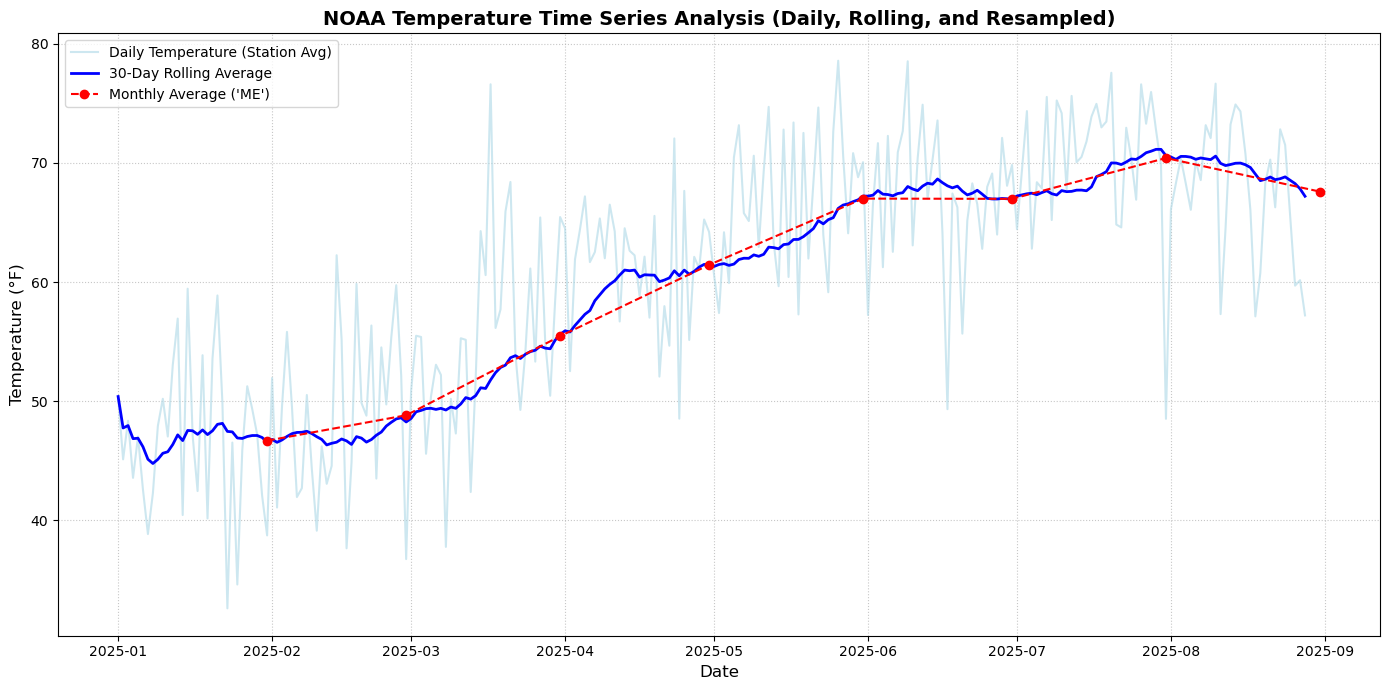

In [10]:
# Compute monthly aggregation from the station-aggregated daily series
monthly_temp = daily_temp.resample("ME").mean()

# Set up the plot size
plt.figure(figsize=(14, 7))

# 1. Plot daily station-averaged readings
plt.plot(
    daily_temp.index,
    daily_temp.values,
    label="Daily Temperature (Station Avg)",
    color="lightblue",
    alpha=0.6,
)

# 2. Plot the 30-day rolling average
plt.plot(
    rolling_30d.index,
    rolling_30d.values,
    label="30-Day Rolling Average",
    color="blue",
    linewidth=2,
)

# 3. Plot the monthly resampled points
plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    label="Monthly Average ('ME')",
    color="red",
    marker="o",
    linestyle="--",
)

# Add title, labels, legend, and grid for readability
plt.title(
    "NOAA Temperature Time Series Analysis (Daily, Rolling, and Resampled)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature (°F)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.7)

# Display the chart
plt.tight_layout()
plt.show()

## Project Conclusion: Time Series Analysis of NOAA Weather Data

### Project Overview
This project demonstrates an end-to-end time series analysis workflow using NOAA Global Surface Summary of the Day weather observations (`noaa - 5000.csv`). The primary objective was to transform raw multi-station meteorological records into a structured temporal series, eliminate instrument sentinel missing values, explore temporal aggregation methods, and reveal seasonal climate trajectories through multi-scale visualization.

---

### Q&A: Key Analytical Questions Addressed

* **How were instrument sensor errors and missing values handled?**  
  NOAA weather datasets represent missing readings with domain-specific sentinel values (`999.9` and `9999.9`) rather than standard blanks. We systematically replaced these sentinels with `NaN` across temperature, dew point, sea level pressure, wind speed, and precipitation attributes so that subsequent analyses use only valid physical measurements.

* **Why convert and sort by a DateTimeIndex?**  
  Converting strings into native Pandas `Timestamp` objects and establishing a monotonic `DatetimeIndex` enabled high-performance date slicing, chronological sorting, and frequency-aware operations across the 240-day span (January 1, 2025 to August 27, 2025).

* **Why aggregate daily across stations before rolling statistics?**  
  The dataset contains multiple station readings per calendar day (~21 observations daily across 239 unique dates). Computing a 30-period rolling average directly across raw rows would only average ~1.5 calendar days of observations across different geographies. Aggregating daily station readings to a single daily mean (`daily_temp = df.groupby('date')['temp'].mean()`) first ensures that a 30-period rolling window represents 30 true calendar days.

* **What is the distinction between Resampling and Rolling Windows in this project?**  
  * **Resampling (`resample('ME')`, `resample('W')`)**: Aggregates data into non-overlapping temporal buckets (monthly/weekly), reducing data dimensionality and providing macro-level baseline statistics.
  * **Rolling Windows (`rolling(window=30)`)**: Computes a moving average over overlapping windows on the daily series, retaining daily temporal resolution while filtering out high-frequency volatility (noise) to highlight medium-term momentum.

---

### Data Analysis Key Findings
* **Dataset Scope**: The dataset encompasses **5,000 observations** spanning **240 calendar days** (239 unique observation dates) between January 1, 2025 and August 27, 2025.
* **Statistical Baselines After Cleaning**: After replacing sentinel missing values, the global mean temperature across all station records was **59.98°F** (std: **29.41°F**), with recorded extremes spanning from **-105.3°F** to **109.4°F**. Sea level pressure averaged **1010.70 hPa**, and mean wind speed stood at **4.80 knots**.
* **Seasonal Temperature Trajectory**: Monthly station-averaged aggregation revealed a consistent warming progression from winter into mid-summer:
  * **January**: `46.68°F`
  * **February**: `48.82°F`
  * **March**: `55.45°F`
  * **April**: `61.44°F`
  * **May**: `67.00°F`
  * **June**: `66.98°F`
  * **July (Seasonal Peak)**: `70.41°F`
  * **August**: `67.59°F`
* **Day-of-Week Patterns**: Daily averages across days of the week ranged from **57.38°F** (Friday) to **61.98°F** (Monday), confirming that weekly cyclicality is minimal compared to the dominant seasonal warming trend.
* **Signal vs. Noise**: Daily station-averaged temperatures fluctuate smoothly between 40°F and 75°F. The **30-day rolling average** filters out short-term fluctuations, mirroring the red dashed monthly average curve and confirming peak summer warming in July.

---

### Insights or Next Steps
* **Station-Level Spatial Decomposition**: Because the dataset aggregates multiple weather stations globally, decomposing the time series by station (`stn`) or geographic climate zone will isolate local climate signatures from global averages.
* **Predictive Time Series Forecasting**: The established temporal structure and cleaned features provide an ideal foundation for training statistical forecasting models (e.g., **ARIMA / SARIMAX** with monthly seasonality) and machine learning models (e.g., **Prophet** or **LSTM**) to predict future seasonal temperature trends.